# Решение задачи кредитного скоринга 
Решение задачи кредитного скоринга будет представлено в нескольких ноутбуках. В данном ноутбуке будет проведена калибровка модели и подбор порогов.

## Данные
Датасет соревнования устроен таким образом, что кредиты для тренировочной выборки взяты за период в М месяцев, а кредиты для тестовой выборки взяты за последующие K месяцев.

Каждая запись кредитной истории содержит самую разнообразную информацию о прошлом кредите клиента, например, сумму, отношение клиента к кредиту, дату открытия и закрытия, информацию о просрочках по платежам и др. Все публикуемые данные тщательно анонимизированы.

Целевая переменная – бинарная величина, принимающая значения 0 и 1, где 1 соответствует дефолту клиента по кредиту.

## Проверка решения
Итоговая метрика решения - ROC AUC. Решения принимаются в виде csv-файла с двумя колонками: “id” – уникальный идентификатор и “score” – предсказание дефолта клиента по кредиту.

## Импорт библиотек

In [1]:
# Импорт библиотек
import json
import sys
import time

sys.path.append('../src')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from xgboost import XGBClassifier

from credit_scoring.models.calibration import PlattCalibrator
from credit_scoring.validation import time_split

RANDOM_STATE = 13

## Чтение датасета и подготовка данных
Читаем сагрегированный датасет, отобранные признаки и параметры модели, разбиваем заявки по времени на train / valid / oot - так же, как в предыдущих ноутбуках.

In [2]:
# Данные, признаки и параметры модели
FEATURES = list(pd.read_csv('../artifacts/features.csv', index_col=0)['feature'])
with open('../artifacts/best_params.json', 'r', encoding='utf-8') as f:
    best_params = json.load(f)

data = pd.read_parquet('../artifacts/aggregated_df.parquet', columns=FEATURES + ['flag'])
data[FEATURES] = data[FEATURES].astype('float32')
train_df, valid_df, oot_df = time_split(data)
del data
best_params

{'max_depth': 5,
 'min_child_weight': 1.6028310982259062,
 'subsample': 0.8813688233629731,
 'colsample_bytree': 0.7488629804880247,
 'reg_lambda': 10.49660026127523,
 'reg_alpha': 3.0004452380967637,
 'learning_rate': 0.03,
 'n_estimators': 2149}

## Обучение модели
Обучаем одну модель XGBoost с параметрами из тюнинга на train. Количество деревьев уже зафиксировано по early stopping, поэтому valid в обучении не участвует - он нужен для калибровки и выбора порогов.

Раньше калиброванная модель была `CalibratedClassifierCV(cv=5)`, то есть ансамблем из 5 бустингов. Теперь модель одна, а калибровка - отдельный маленький шаг поверх неё. Так SHAP будет объяснять ровно ту модель, что принимает решения.

In [3]:
# Обучение итоговой модели на train
start = time.time()
model = XGBClassifier(**best_params, tree_method='hist', random_state=RANDOM_STATE)
model.fit(train_df[FEATURES], train_df['flag'])
print(f"Время обучения: {time.time() - start:.0f} s")

# Сохраним модель в нативном формате XGBoost - он не зависит от версий sklearn/pickle
model.save_model('../models/xgb_model.json')

Время обучения: 184 s


In [4]:
# Сырые вероятности на valid и oot
y_valid, y_oot = valid_df['flag'].to_numpy(), oot_df['flag'].to_numpy()
raw_valid = model.predict_proba(valid_df[FEATURES])[:, 1]
raw_oot = model.predict_proba(oot_df[FEATURES])[:, 1]

def prob_metrics(y, p):
    """Метрики качества ранжирования и вероятностей."""
    return {
        'roc_auc': roc_auc_score(y, p),
        'log_loss': log_loss(y, p),
        'brier': brier_score_loss(y, p),
        'mean_proba': p.mean(),
        'default_rate': y.mean(),
    }

pd.DataFrame({'valid': prob_metrics(y_valid, raw_valid), 'oot': prob_metrics(y_oot, raw_oot)}).T

,roc_auc,log_loss,brier,mean_proba,default_rate
valid,0.756025,0.139692,0.033384,0.033359,0.035908
oot,0.744142,0.133062,0.031148,0.033689,0.033172


Модель без `scale_pos_weight` почти откалибрована: средняя предсказанная вероятность 3.34% при фактическом уровне дефолта 3.59% на valid и 3.37% при 3.32% на oot.

Обратим внимание на дрейф: модель недооценивает риск на valid и почти точно попадает в средний уровень на oot - уровень дефолта во времени меняется (3.6% → 3.3%), и калибровка, подобранная на одном периоде, на другом будет немного смещена.

## Калибровка
Сравним два способа калибровки:
- **Platt scaling** на логите вероятности - монотонное преобразование с двумя параметрами, устойчивое к переобучению;
- **Isotonic regression** - непараметрическая монотонная функция, гибче, но может переобучаться и создаёт ступеньки (одинаковые вероятности у разных заявок).

Чтобы выбрать способ, не трогая oot, разделим valid пополам по времени: калибруем на первой половине, оцениваем на второй.

In [5]:
# Выбор способа калибровки на двух половинах valid
half = len(y_valid) // 2
fit_p, fit_y = raw_valid[:half], y_valid[:half]
eval_p, eval_y = raw_valid[half:], y_valid[half:]

platt_half = PlattCalibrator().fit(fit_p, fit_y)
iso_half = IsotonicRegression(out_of_bounds='clip', y_min=1e-6, y_max=1 - 1e-6).fit(fit_p, fit_y)

pd.DataFrame({
    'raw': prob_metrics(eval_y, eval_p),
    'platt': prob_metrics(eval_y, platt_half.predict(eval_p)),
    'isotonic': prob_metrics(eval_y, iso_half.predict(eval_p)),
}).T

,roc_auc,log_loss,brier,mean_proba,default_rate
raw,0.758148,0.135052,0.032070,0.032535,0.034457
platt,0.758148,0.134932,0.032050,0.035694,0.034457
isotonic,0.757728,0.134956,0.032044,0.035602,0.034457


Оба способа почти не меняют качество вероятностей: log loss 0.1351 → 0.1349, Brier 0.03207 → 0.03205. Isotonic не лучше Platt и чуть снижает ROC-AUC (0.7577 против 0.7581) из-за ступенек - одинаковых вероятностей у разных заявок. Выбираем Platt scaling: он не меняет ранжирование, имеет всего 2 параметра и хранится в json.

In [6]:
# Итоговый калибратор - Platt scaling на всём valid
calibrator = PlattCalibrator().fit(raw_valid, y_valid)
calibrator.save('../models/calibrator.json')
print(f"a = {calibrator.a:.4f}, b = {calibrator.b:.4f}")

cal_valid = calibrator.predict(raw_valid)
cal_oot = calibrator.predict(raw_oot)
pd.DataFrame({
    'oot raw': prob_metrics(y_oot, raw_oot),
    'oot calibrated': prob_metrics(y_oot, cal_oot),
}).T

a = 0.9219, b = -0.1496


,roc_auc,log_loss,brier,mean_proba,default_rate
oot raw,0.744142,0.133062,0.031148,0.033689,0.033172
oot calibrated,0.744142,0.132989,0.031131,0.036263,0.033172


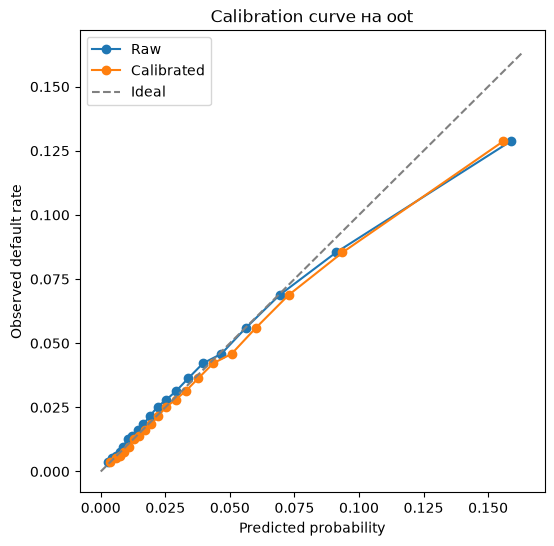

In [7]:
# Calibration curve на oot
fig, ax = plt.subplots(figsize=(6, 6))
for name, p in {'Raw': raw_oot, 'Calibrated': cal_oot}.items():
    prob_true, prob_pred = calibration_curve(y_oot, p, n_bins=20, strategy='quantile')
    ax.plot(prob_pred, prob_true, 'o-', label=name)
lim = max(prob_pred.max(), prob_true.max()) * 1.05
ax.plot([0, lim], [0, lim], '--', color='gray', label='Ideal')
ax.set_xlabel('Predicted probability')
ax.set_ylabel('Observed default rate')
ax.set_title('Calibration curve на oot')
ax.legend()
plt.show()

Выводы:
- калибровка почти ничего не меняет: модель и без неё близка к диагонали, ROC-AUC не меняется (преобразование монотонное), log loss на oot улучшается менее чем на 0.0001;
- на oot откалиброванная модель немного завышает средний риск (3.63% против фактических 3.32%): калибратор подстроился под уровень дефолта valid, а на oot он ниже. Это прямое следствие дрейфа - в продуктовой системе калибровку нужно периодически переподбирать на свежих данных;
- в правом хвосте (самые рискованные 5% заявок) обе версии завышают риск: предсказано ~16%, фактически ~13%;
- шаг калибровки оставляем в пайплайне как дешёвую страховку: если модель изменится (например, вернутся веса классов или появится нейросеть), он восстановит масштаб вероятностей.

## Выбор порога
Заявка одобряется, если откалиброванная вероятность дефолта ниже порога. Пороги подбираем на valid, а итоговую политику проверяем на oot.

Для каждого порога считаем:
- `approval_rate` - доля одобренных заявок;
- `default_rate_approved` - уровень дефолта среди одобренных (риск портфеля);
- `defaults_caught` - доля всех дефолтов, отсечённых отказом;
- `precision_reject` - доля дефолтников среди отказов.

Сетку порогов строим по квантилям скора, чтобы шаг по доле одобрения был равномерным (0.5%).

In [8]:
def policy_table(y, score, thresholds):
    """Метрики кредитной политики «одобряем, если score < threshold» для каждого порога."""
    n_defaults = y.sum()
    rows = []
    for t in thresholds:
        approved = score < t
        rejected = ~approved
        rows.append({
            'threshold': t,
            'approval_rate': approved.mean(),
            'default_rate_approved': y[approved].mean() if approved.any() else np.nan,
            'defaults_caught': (rejected & (y == 1)).sum() / n_defaults,
            'precision_reject': y[rejected].mean() if rejected.any() else np.nan,
        })
    return pd.DataFrame(rows)

thresholds = np.unique(np.quantile(cal_valid, np.linspace(0.2, 1.0, 161)))
policy_valid = policy_table(y_valid, cal_valid, thresholds)
policy_oot = policy_table(y_oot, cal_oot, thresholds)
policy_valid.iloc[::20]

,threshold,approval_rate,default_rate_approved,defaults_caught,precision_reject
0,0.009953,0.199997,0.005258,0.970712,0.043571
20,0.013673,0.300000,0.006867,0.942632,0.048355
40,0.018118,0.400000,0.009092,0.898724,0.053786
60,0.023689,0.500000,0.011490,0.840009,0.060327
80,0.030768,0.600000,0.014158,0.763425,0.068533
100,0.040292,0.700000,0.017502,0.658807,0.078856
120,0.054333,0.800000,0.021244,0.526712,0.094567
140,0.080306,0.900000,0.026550,0.334556,0.120133
160,0.668258,0.999998,0.035907,0.000046,1.000000


Выберем пороги под три сценария допустимого риска портфеля. Базовый уровень дефолта ~3.6%, поэтому сценарии задаём заметно ниже него, иначе отказывать почти не придётся:
- **strict** - риск среди одобренных не больше 1.5%;
- **base** - не больше 2.5%;
- **soft** - не больше 3.0%.

Для каждого сценария берём порог с максимальной долей одобрения, при которой риск на valid не превышает целевой.

In [9]:
# Подбор порогов на valid и проверка на oot
target_risks = {'strict': 0.015, 'base': 0.025, 'soft': 0.030}

chosen = {}
for name, target in target_risks.items():
    candidates = policy_valid[policy_valid['default_rate_approved'] <= target]
    if candidates.empty:
        print(f"{name}: нет порога с риском <= {target}")
        continue
    t = candidates.loc[candidates['approval_rate'].idxmax(), 'threshold']
    chosen[name] = {'target_risk': target, 'threshold': float(t)}

rows = []
for name, c in chosen.items():
    for sample, y, score in [('valid', y_valid, cal_valid), ('oot', y_oot, cal_oot)]:
        row = policy_table(y, score, [c['threshold']]).iloc[0].to_dict()
        rows.append({'scenario': name, 'sample': sample, 'target_risk': c['target_risk'], **row})
pd.DataFrame(rows).set_index(['scenario', 'sample']).round(4)

target_risk  threshold  approval_rate  default_rate_approved  \
scenario sample                                                                 
strict   valid         0.015     0.0329         0.6250                 0.0149   
         oot           0.015     0.0329         0.6237                 0.0147   
base     valid         0.025     0.0702         0.8700                 0.0247   
         oot           0.025     0.0702         0.8678                 0.0233   
soft     valid         0.030     0.1042         0.9450                 0.0298   
         oot           0.030     0.1042         0.9431                 0.0277   

                 defaults_caught  precision_reject  
scenario sample                                     
strict   valid            0.7409            0.0709  
         oot              0.7228            0.0637  
base     valid            0.4014            0.1109  
         oot              0.3913            0.0981  
soft     valid            0.2155            0.1407  
         oot              0.2137            0.1245

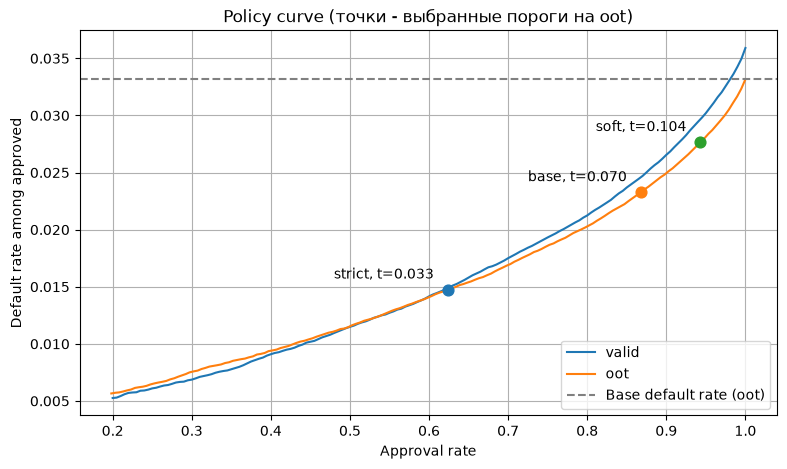

In [10]:
# Policy curve на valid и oot с выбранными порогами
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(policy_valid['approval_rate'], policy_valid['default_rate_approved'], label='valid')
ax.plot(policy_oot['approval_rate'], policy_oot['default_rate_approved'], label='oot')
for name, c in chosen.items():
    point = policy_table(y_oot, cal_oot, [c['threshold']]).iloc[0]
    ax.scatter(point['approval_rate'], point['default_rate_approved'], s=60, zorder=3)
    ax.annotate(f"{name}, t={c['threshold']:.3f}", (point['approval_rate'], point['default_rate_approved']),
                textcoords='offset points', xytext=(-10, 8), ha='right')
ax.axhline(y_oot.mean(), linestyle='--', color='gray', label='Base default rate (oot)')
ax.set_xlabel('Approval rate')
ax.set_ylabel('Default rate among approved')
ax.set_title('Policy curve (точки - выбранные пороги на oot)')
ax.legend()
ax.grid(True)
plt.show()

Выводы:
- пороги, подобранные на valid, хорошо переносятся на oot: доля одобрения почти не меняется (62% / 87% / 94%), а риск портфеля на oot во всех трёх сценариях не превышает целевой (1.47%, 2.33%, 2.77%);
- на oot кривая в зоне высокой доли одобрения лежит ниже, чем на valid - дефолтов в более поздний период меньше;
- сценарий base (риск ≤ 2.5%) одобряет 87% заявок и отсекает 39% всех дефолтов, при этом среди отказов дефолтников ~10% - в 3 раза больше среднего уровня. Сценарий strict отсекает 72% дефолтов при одобрении 62% заявок;
- по сравнению с моделью на прежних признаках при том же целевом риске одобряется больше заявок: strict 54% → 62%, base 83% → 87%. Лучшее ранжирование напрямую превращается в бизнес-эффект - больше одобренных клиентов без роста риска.

In [11]:
# Сохраним пороги вместе с целевым риском
with open('../artifacts/thresholds.json', 'w', encoding='utf-8') as f:
    json.dump(chosen, f, ensure_ascii=False, indent=4)
chosen

{'strict': {'target_risk': 0.015, 'threshold': 0.03290017694234848},
 'base': {'target_risk': 0.025, 'threshold': 0.07023406110703961},
 'soft': {'target_risk': 0.03, 'threshold': 0.1042138332501054}}

## Итоги
1. Итоговая модель - один XGBoost, обученный на train, сохранён в нативном формате: `models/xgb_model.json`. SHAP будет объяснять именно её.
2. Калибровка - Platt scaling на логите, подобран на valid: `models/calibrator.json` (2 параметра). Модель без весов классов и так почти откалибрована, калибровка оставлена как дешёвая страховка.
3. Пороги подобраны на valid под три сценария риска и проверены на oot: `artifacts/thresholds.json` (порог + целевой риск). Основной сценарий - base: риск ≤ 2.5%, порог ≈ 0.070, на oot одобряется 87% заявок при риске 2.33%.
4. Из-за дрейфа уровень дефолта и калибровка во времени смещаются - в продуктовой системе нужен мониторинг и периодический пересчёт калибровки и порогов.

Далее - интерпретация модели через SHAP.